Adult ICU observations: 1096
Date range: 10/02/2023 — 09/02/2026

=== Cluster Validation — Adult ICUs ===

  k    Silhouette   Davies-Bouldin
-----------------------------------
  2        0.5379           0.6760
  3        0.4735           0.6941
  4        0.4551           0.8024
  5        0.4781           0.7504
  6        0.4878           0.6999
  7        0.4888           0.7141
  8        0.4828           0.7910
  9        0.4888           0.7373
 10        0.4887           0.7352

=== Optimal k ===
  Silhouette (highest):       k = 2  (0.5379)
  Davies-Bouldin (lowest):    k = 2  (0.6760)


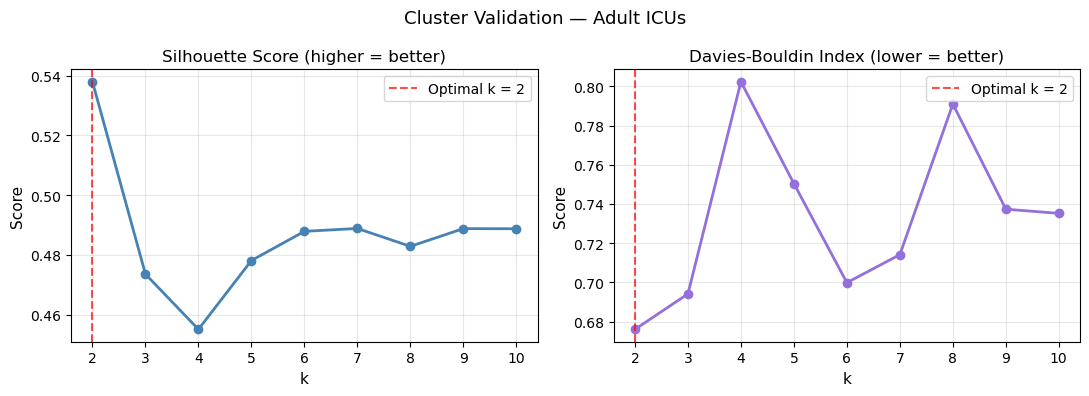


Overall Silhouette Score (k=2): 0.5379

=== Cluster Characterization (k = 2) ===

  Cluster 0:  n = 356 (32.5%)
    Per-cluster silhouette score: 0.4639
    Negative silhouette observations: 0 (0.00%)
    utilization_rate              mean = 0.8694  (SD = 0.0163)
    slack_rate                    mean = 0.1306  (SD = 0.0163)
    staff_constraint_rate         mean = 0.4039  (SD = 0.0510)
    space_constraint_rate         mean = 0.1410  (SD = 0.0212)
    material_constraint_rate      mean = 0.0000  (SD = 0.0000)

  Cluster 1:  n = 740 (67.5%)
    Per-cluster silhouette score: 0.5735
    Negative silhouette observations: 0 (0.00%)
    utilization_rate              mean = 0.8441  (SD = 0.0169)
    slack_rate                    mean = 0.1559  (SD = 0.0169)
    staff_constraint_rate         mean = 0.2792  (SD = 0.0455)
    space_constraint_rate         mean = 0.0906  (SD = 0.0153)
    material_constraint_rate      mean = 0.0000  (SD = 0.0000)

=== Cluster Centroids (z-score scale) ===
  Clu

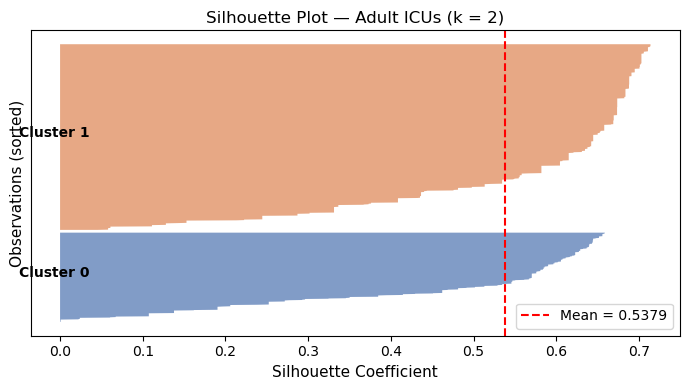

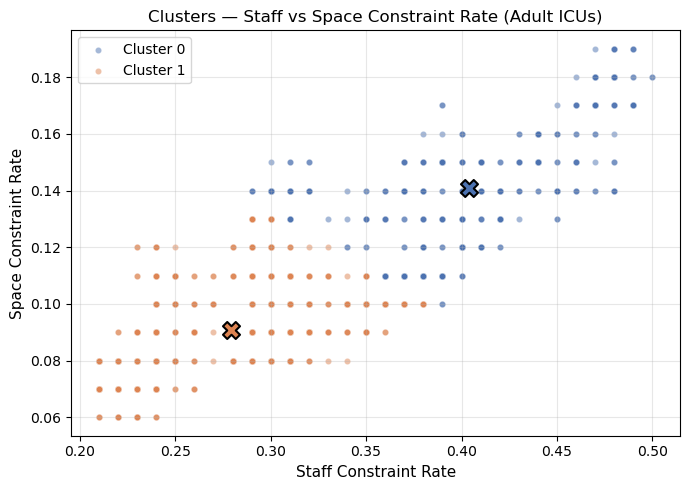

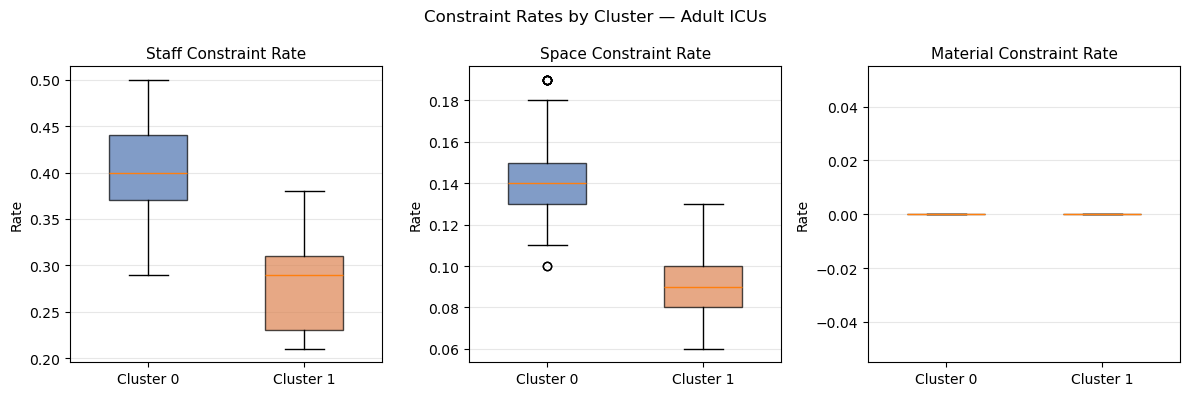


=== Done ===


In [52]:
#ICU ADULT VISUAL

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Load data and filter adults
# ──────────────────────────────────────────────
df = pd.read_csv('Intensivregister_file.csv', sep=';', decimal=',', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

numeric_cols = ['reporting_units', 'current_covid_cases', 'icu_beds_occupied', 'icu_beds_available',
                'material_constraints', 'staff_constraints', 'space_constraints', 'total_icu_capacity',
                'utilization_rate', 'slack_rate', 'staff_constraint_rate', 'material_constraint_rate',
                'space_constraint_rate', 'utilization_rate_z', 'slack_rate_z',
                'staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

adults = df[df['care_group'] == 'ERWACHSENE'].copy()
adults.reset_index(drop=True, inplace=True)

print(f"Adult ICU observations: {len(adults)}")
print(f"Date range: {adults['date'].iloc[0]} — {adults['date'].iloc[-1]}")

# ──────────────────────────────────────────────
# 2. Features (z-scores)
# ──────────────────────────────────────────────
features_z = ['staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']
X = adults[features_z].values

# ──────────────────────────────────────────────
# 3. Silhouette + Davies-Bouldin for k = 2 to 10
# ──────────────────────────────────────────────
sil_scores = {}
dav_scores = {}

print("\n=== Cluster Validation — Adult ICUs ===\n")
print(f"{'k':>3}  {'Silhouette':>12}  {'Davies-Bouldin':>15}")
print("-" * 35)

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    sil = silhouette_score(X, labels)
    dav = davies_bouldin_score(X, labels)
    sil_scores[k] = sil
    dav_scores[k] = dav
    print(f"{k:>3}  {sil:>12.4f}  {dav:>15.4f}")

best_sil = max(sil_scores, key=sil_scores.get)
best_dav = min(dav_scores, key=dav_scores.get)

print(f"\n=== Optimal k ===")
print(f"  Silhouette (highest):       k = {best_sil}  ({sil_scores[best_sil]:.4f})")
print(f"  Davies-Bouldin (lowest):    k = {best_dav}  ({dav_scores[best_dav]:.4f})")

# ──────────────────────────────────────────────
# 4. PLOT — Silhouette + Davies-Bouldin
# ──────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ks = list(sil_scores.keys())
ax1.plot(ks, list(sil_scores.values()), 'o-', color='steelblue', linewidth=2, markersize=6)
ax1.axvline(best_sil, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_sil}')
ax1.set_xlabel('k', fontsize=11)
ax1.set_ylabel('Score', fontsize=11)
ax1.set_title('Silhouette Score (higher = better)', fontsize=12)
ax1.set_xticks(ks)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(ks, list(dav_scores.values()), 'o-', color='mediumpurple', linewidth=2, markersize=6)
ax2.axvline(best_dav, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_dav}')
ax2.set_xlabel('k', fontsize=11)
ax2.set_ylabel('Score', fontsize=11)
ax2.set_title('Davies-Bouldin Index (lower = better)', fontsize=12)
ax2.set_xticks(ks)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('Cluster Validation — Adult ICUs', fontsize=13)
plt.tight_layout()
plt.savefig('H1_adults_validation.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 5. K-Means with k = 2
# ──────────────────────────────────────────────
km = KMeans(n_clusters=2, n_init=10, random_state=42)
adults['cluster'] = km.fit_predict(X)

overall_sil = silhouette_score(X, adults['cluster'].values)
sil_vals = silhouette_samples(X, adults['cluster'].values)
adults['silhouette'] = sil_vals

print(f"\nOverall Silhouette Score (k=2): {overall_sil:.4f}")

# ──────────────────────────────────────────────
# 6. Cluster characterization
# ──────────────────────────────────────────────
report_vars = ['utilization_rate', 'slack_rate',
               'staff_constraint_rate', 'space_constraint_rate',
               'material_constraint_rate']

print(f"\n=== Cluster Characterization (k = 2) ===")
for c in sorted(adults['cluster'].unique()):
    mask = adults['cluster'] == c
    n = mask.sum()
    pct = n / len(adults) * 100
    neg_sil = (adults.loc[mask, 'silhouette'] < 0).sum()
    neg_pct = neg_sil / n * 100
    mean_sil = adults.loc[mask, 'silhouette'].mean()

    print(f"\n  Cluster {c}:  n = {n} ({pct:.1f}%)")
    print(f"    Per-cluster silhouette score: {mean_sil:.4f}")
    print(f"    Negative silhouette observations: {neg_sil} ({neg_pct:.2f}%)")
    for v in report_vars:
        m = adults.loc[mask, v].mean()
        s = adults.loc[mask, v].std()
        print(f"    {v:<28s}  mean = {m:.4f}  (SD = {s:.4f})")

# ──────────────────────────────────────────────
# 7. Centroids (z-score scale)
# ──────────────────────────────────────────────
print(f"\n=== Cluster Centroids (z-score scale) ===")
for c in range(2):
    vals = ', '.join([f"{features_z[i]} = {km.cluster_centers_[c, i]:.4f}" for i in range(len(features_z))])
    print(f"  Cluster {c}: {vals}")

# ──────────────────────────────────────────────
# 8. PLOT — Silhouette coefficient per cluster
# ──────────────────────────────────────────────
cluster_colors = ['#4C72B0', '#DD8452']

fig, ax = plt.subplots(figsize=(7, 4))
y_lower = 10

for c in sorted(adults['cluster'].unique()):
    cluster_sil = np.sort(sil_vals[adults['cluster'].values == c])
    size = len(cluster_sil)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                      facecolor=cluster_colors[c], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size, f'Cluster {c}', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

ax.axvline(x=overall_sil, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {overall_sil:.4f}')
ax.set_xlabel('Silhouette Coefficient', fontsize=11)
ax.set_ylabel('Observations (sorted)', fontsize=11)
ax.set_title('Silhouette Plot — Adult ICUs (k = 2)', fontsize=12)
ax.legend(fontsize=10)
ax.set_yticks([])
plt.tight_layout()
plt.savefig('H1_adults_silhouette_plot.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 9. PLOT — Scatter staff vs space by cluster
# ──────────────────────────────────────────────
centroids_orig = []
for c in range(2):
    means = [adults.loc[adults['cluster'] == c, f.replace('_z', '')].mean() for f in features_z]
    centroids_orig.append(means)

fig, ax = plt.subplots(figsize=(7, 5))
for c in sorted(adults['cluster'].unique()):
    mask = adults['cluster'] == c
    ax.scatter(adults.loc[mask, 'staff_constraint_rate'],
               adults.loc[mask, 'space_constraint_rate'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.5, s=20, edgecolors='w', linewidth=0.3)

for c in range(2):
    ax.scatter(centroids_orig[c][0], centroids_orig[c][2],
               c=cluster_colors[c], marker='X', s=150, edgecolors='black', linewidth=1.5, zorder=5)

ax.set_xlabel('Staff Constraint Rate', fontsize=11)
ax.set_ylabel('Space Constraint Rate', fontsize=11)
ax.set_title('Clusters — Staff vs Space Constraint Rate (Adult ICUs)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('H1_adults_scatter_staff_space.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 10. PLOT — Boxplots constraint rates by cluster
# ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
box_vars = ['staff_constraint_rate', 'space_constraint_rate', 'material_constraint_rate']
box_titles = ['Staff Constraint Rate', 'Space Constraint Rate', 'Material Constraint Rate']

for ax, var, title in zip(axes, box_vars, box_titles):
    data_list = [adults.loc[adults['cluster'] == c, var].values for c in sorted(adults['cluster'].unique())]
    bp = ax.boxplot(data_list, tick_labels=['Cluster 0', 'Cluster 1'], patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], cluster_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Rate', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Constraint Rates by Cluster — Adult ICUs', fontsize=12)
plt.tight_layout()
plt.savefig('H1_adults_boxplots.png', dpi=150)
plt.show()

print("\n=== Done ===")

PICU observations: 1096
Date range: 10/02/2023 — 09/02/2026

=== Cluster Validation — PICU ===

  k    Silhouette   Davies-Bouldin
-----------------------------------
  2        0.6578           0.5287
  3        0.5764           0.7399
  4        0.4101           0.9182
  5        0.3759           0.9613
  6        0.3959           0.8407
  7        0.3709           0.8662
  8        0.3896           0.8041
  9        0.4096           0.7780
 10        0.3962           0.8116

=== Optimal k ===
  Silhouette (highest):       k = 2  (0.6578)
  Davies-Bouldin (lowest):    k = 2  (0.5287)


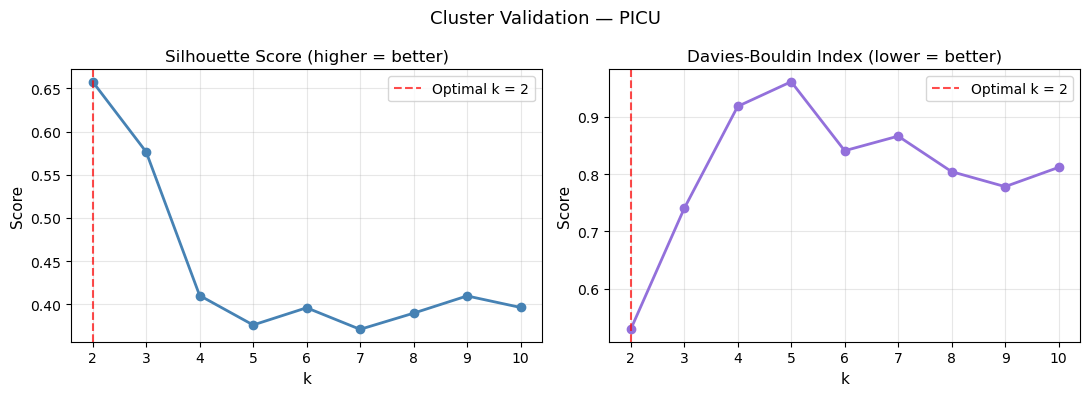


Overall Silhouette Score (k=2): 0.6578

=== Cluster Characterization (k = 2) ===

  Cluster 0:  n = 445 (40.6%)
    Per-cluster silhouette score: 0.5809
    Negative silhouette observations: 0 (0.00%)
    utilization_rate              mean = 0.6708  (SD = 0.0381)
    slack_rate                    mean = 0.3292  (SD = 0.0381)
    staff_constraint_rate         mean = 0.3309  (SD = 0.0409)
    space_constraint_rate         mean = 0.1212  (SD = 0.0297)
    material_constraint_rate      mean = 0.0100  (SD = 0.0000)

  Cluster 1:  n = 651 (59.4%)
    Per-cluster silhouette score: 0.7103
    Negative silhouette observations: 0 (0.00%)
    utilization_rate              mean = 0.6129  (SD = 0.0360)
    slack_rate                    mean = 0.3871  (SD = 0.0360)
    staff_constraint_rate         mean = 0.2161  (SD = 0.0306)
    space_constraint_rate         mean = 0.0733  (SD = 0.0191)
    material_constraint_rate      mean = 0.0000  (SD = 0.0000)

=== Cluster Centroids (z-score scale) ===
  Clu

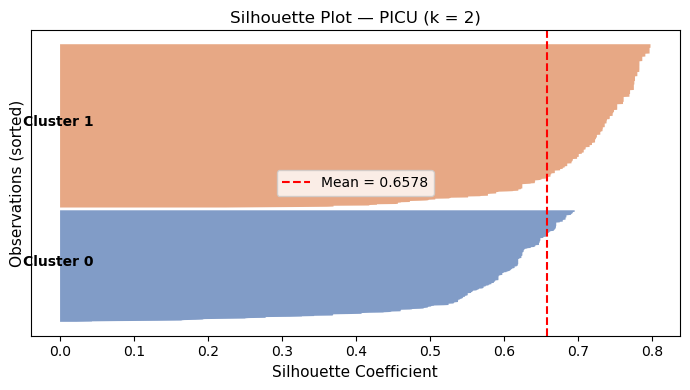

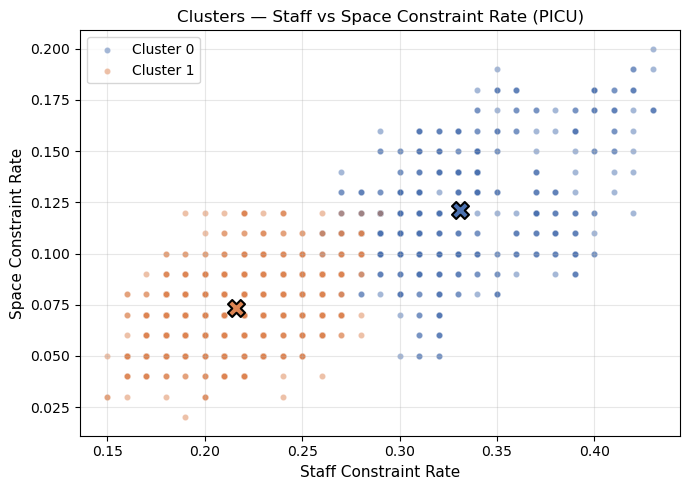

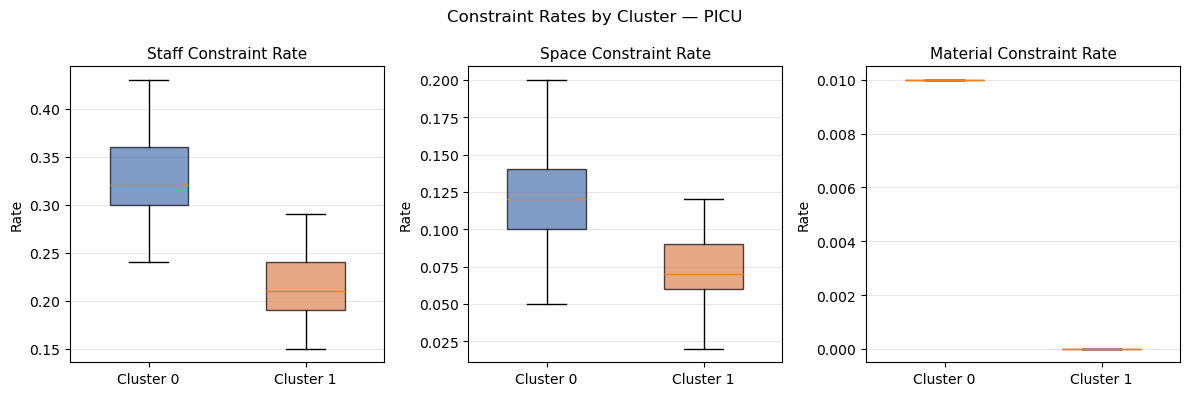


=== Done ===


In [54]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Load data and filter PICU
# ──────────────────────────────────────────────
df = pd.read_csv('Intensivregister_file.csv', sep=';', decimal=',', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

numeric_cols = ['reporting_units', 'current_covid_cases', 'icu_beds_occupied', 'icu_beds_available',
                'material_constraints', 'staff_constraints', 'space_constraints', 'total_icu_capacity',
                'utilization_rate', 'slack_rate', 'staff_constraint_rate', 'material_constraint_rate',
                'space_constraint_rate', 'utilization_rate_z', 'slack_rate_z',
                'staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

picu = df[df['care_group'] == 'PICU'].copy()
picu.reset_index(drop=True, inplace=True)

print(f"PICU observations: {len(picu)}")
print(f"Date range: {picu['date'].iloc[0]} — {picu['date'].iloc[-1]}")

# ──────────────────────────────────────────────
# 2. Features (z-scores)
# ──────────────────────────────────────────────
features_z = ['staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']
X = picu[features_z].values

# ──────────────────────────────────────────────
# 3. Silhouette + Davies-Bouldin for k = 2 to 10
# ──────────────────────────────────────────────
sil_scores = {}
dav_scores = {}

print("\n=== Cluster Validation — PICU ===\n")
print(f"{'k':>3}  {'Silhouette':>12}  {'Davies-Bouldin':>15}")
print("-" * 35)

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    sil = silhouette_score(X, labels)
    dav = davies_bouldin_score(X, labels)
    sil_scores[k] = sil
    dav_scores[k] = dav
    print(f"{k:>3}  {sil:>12.4f}  {dav:>15.4f}")

best_sil = max(sil_scores, key=sil_scores.get)
best_dav = min(dav_scores, key=dav_scores.get)

print(f"\n=== Optimal k ===")
print(f"  Silhouette (highest):       k = {best_sil}  ({sil_scores[best_sil]:.4f})")
print(f"  Davies-Bouldin (lowest):    k = {best_dav}  ({dav_scores[best_dav]:.4f})")

# ──────────────────────────────────────────────
# 4. PLOT — Silhouette + Davies-Bouldin
# ──────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ks = list(sil_scores.keys())
ax1.plot(ks, list(sil_scores.values()), 'o-', color='steelblue', linewidth=2, markersize=6)
ax1.axvline(best_sil, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_sil}')
ax1.set_xlabel('k', fontsize=11)
ax1.set_ylabel('Score', fontsize=11)
ax1.set_title('Silhouette Score (higher = better)', fontsize=12)
ax1.set_xticks(ks)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(ks, list(dav_scores.values()), 'o-', color='mediumpurple', linewidth=2, markersize=6)
ax2.axvline(best_dav, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_dav}')
ax2.set_xlabel('k', fontsize=11)
ax2.set_ylabel('Score', fontsize=11)
ax2.set_title('Davies-Bouldin Index (lower = better)', fontsize=12)
ax2.set_xticks(ks)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('Cluster Validation — PICU', fontsize=13)
plt.tight_layout()
plt.savefig('H1_picu_validation.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 5. K-Means with k = 2
# ──────────────────────────────────────────────
km = KMeans(n_clusters=2, n_init=10, random_state=42)
picu['cluster'] = km.fit_predict(X)

overall_sil = silhouette_score(X, picu['cluster'].values)
sil_vals = silhouette_samples(X, picu['cluster'].values)
picu['silhouette'] = sil_vals

print(f"\nOverall Silhouette Score (k=2): {overall_sil:.4f}")

# ──────────────────────────────────────────────
# 6. Cluster characterization
# ──────────────────────────────────────────────
report_vars = ['utilization_rate', 'slack_rate',
               'staff_constraint_rate', 'space_constraint_rate',
               'material_constraint_rate']

print(f"\n=== Cluster Characterization (k = 2) ===")
for c in sorted(picu['cluster'].unique()):
    mask = picu['cluster'] == c
    n = mask.sum()
    pct = n / len(picu) * 100
    neg_sil = (picu.loc[mask, 'silhouette'] < 0).sum()
    neg_pct = neg_sil / n * 100
    mean_sil = picu.loc[mask, 'silhouette'].mean()

    print(f"\n  Cluster {c}:  n = {n} ({pct:.1f}%)")
    print(f"    Per-cluster silhouette score: {mean_sil:.4f}")
    print(f"    Negative silhouette observations: {neg_sil} ({neg_pct:.2f}%)")
    for v in report_vars:
        m = picu.loc[mask, v].mean()
        s = picu.loc[mask, v].std()
        print(f"    {v:<28s}  mean = {m:.4f}  (SD = {s:.4f})")

# ──────────────────────────────────────────────
# 7. Centroids (z-score scale)
# ──────────────────────────────────────────────
print(f"\n=== Cluster Centroids (z-score scale) ===")
for c in range(2):
    vals = ', '.join([f"{features_z[i]} = {km.cluster_centers_[c, i]:.4f}" for i in range(len(features_z))])
    print(f"  Cluster {c}: {vals}")

# ──────────────────────────────────────────────
# 8. PLOT — Silhouette coefficient per cluster
# ──────────────────────────────────────────────
cluster_colors = ['#4C72B0', '#DD8452']

fig, ax = plt.subplots(figsize=(7, 4))
y_lower = 10

for c in sorted(picu['cluster'].unique()):
    cluster_sil = np.sort(sil_vals[picu['cluster'].values == c])
    size = len(cluster_sil)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                      facecolor=cluster_colors[c], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size, f'Cluster {c}', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

ax.axvline(x=overall_sil, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {overall_sil:.4f}')
ax.set_xlabel('Silhouette Coefficient', fontsize=11)
ax.set_ylabel('Observations (sorted)', fontsize=11)
ax.set_title('Silhouette Plot — PICU (k = 2)', fontsize=12)
ax.legend(fontsize=10)
ax.set_yticks([])
plt.tight_layout()
plt.savefig('H1_picu_silhouette_plot.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 9. PLOT — Scatter staff vs space by cluster
# ──────────────────────────────────────────────
centroids_orig = []
for c in range(2):
    means = [picu.loc[picu['cluster'] == c, f.replace('_z', '')].mean() for f in features_z]
    centroids_orig.append(means)

fig, ax = plt.subplots(figsize=(7, 5))
for c in sorted(picu['cluster'].unique()):
    mask = picu['cluster'] == c
    ax.scatter(picu.loc[mask, 'staff_constraint_rate'],
               picu.loc[mask, 'space_constraint_rate'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.5, s=20, edgecolors='w', linewidth=0.3)

for c in range(2):
    ax.scatter(centroids_orig[c][0], centroids_orig[c][2],
               c=cluster_colors[c], marker='X', s=150, edgecolors='black', linewidth=1.5, zorder=5)

ax.set_xlabel('Staff Constraint Rate', fontsize=11)
ax.set_ylabel('Space Constraint Rate', fontsize=11)
ax.set_title('Clusters — Staff vs Space Constraint Rate (PICU)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('H1_picu_scatter_staff_space.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 10. PLOT — Boxplots constraint rates by cluster
# ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
box_vars = ['staff_constraint_rate', 'space_constraint_rate', 'material_constraint_rate']
box_titles = ['Staff Constraint Rate', 'Space Constraint Rate', 'Material Constraint Rate']

for ax, var, title in zip(axes, box_vars, box_titles):
    data_list = [picu.loc[picu['cluster'] == c, var].values for c in sorted(picu['cluster'].unique())]
    bp = ax.boxplot(data_list, tick_labels=['Cluster 0', 'Cluster 1'], patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], cluster_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Rate', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Constraint Rates by Cluster — PICU', fontsize=12)
plt.tight_layout()
plt.savefig('H1_picu_boxplots.png', dpi=150)
plt.show()

print("\n=== Done ===")

NICU observations: 1096
Date range: 10/02/2023 — 09/02/2026

=== Cluster Validation — NICU ===

  k    Silhouette   Davies-Bouldin
-----------------------------------
  2        0.5505           1.0071
  3        0.5888           0.5705
  4        0.4638           0.6467
  5        0.4405           0.6801
  6        0.4485           0.6950
  7        0.4451           0.7057
  8        0.4538           0.6853
  9        0.4425           0.7121
 10        0.4285           0.7161

=== Optimal k ===
  Silhouette (highest):       k = 3  (0.5888)
  Davies-Bouldin (lowest):    k = 3  (0.5705)


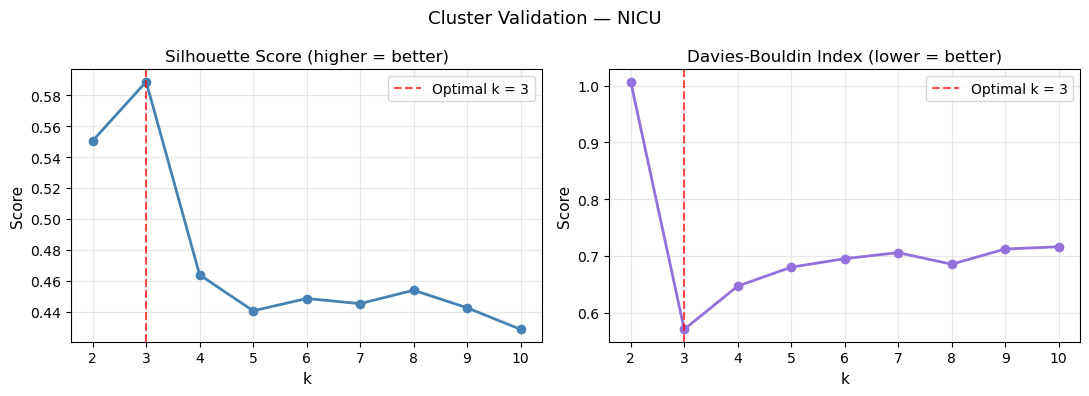


Overall Silhouette Score (k=2): 0.5888

=== Cluster Characterization (k = 3) ===

  Cluster 0:  n = 797 (72.7%)
    Per-cluster silhouette score: 0.6009
    Negative silhouette observations: 6 (0.75%)
    utilization_rate              mean = 0.6468  (SD = 0.0262)
    slack_rate                    mean = 0.3532  (SD = 0.0262)
    staff_constraint_rate         mean = 0.1776  (SD = 0.0381)
    space_constraint_rate         mean = 0.0608  (SD = 0.0149)
    material_constraint_rate      mean = 0.0100  (SD = 0.0000)

  Cluster 1:  n = 71 (6.5%)
    Per-cluster silhouette score: 0.7709
    Negative silhouette observations: 0 (0.00%)
    utilization_rate              mean = 0.6876  (SD = 0.0126)
    slack_rate                    mean = 0.3124  (SD = 0.0126)
    staff_constraint_rate         mean = 0.2777  (SD = 0.0293)
    space_constraint_rate         mean = 0.0811  (SD = 0.0181)
    material_constraint_rate      mean = 0.0200  (SD = 0.0000)

  Cluster 2:  n = 228 (20.8%)
    Per-cluster sil

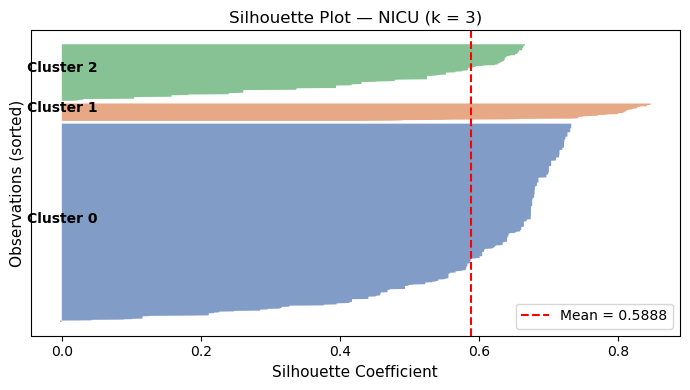

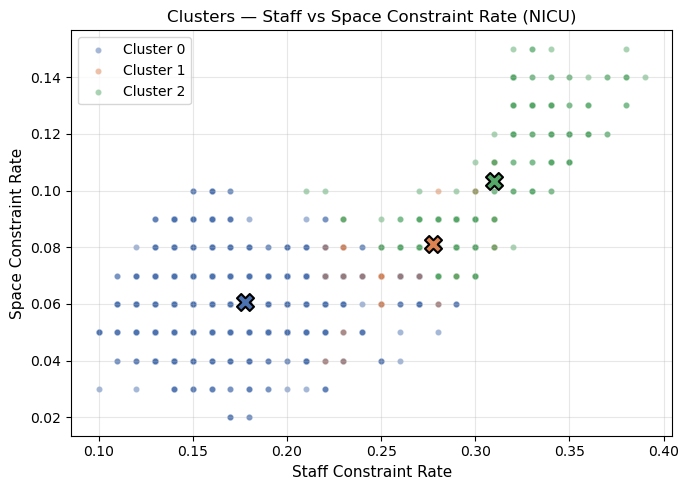

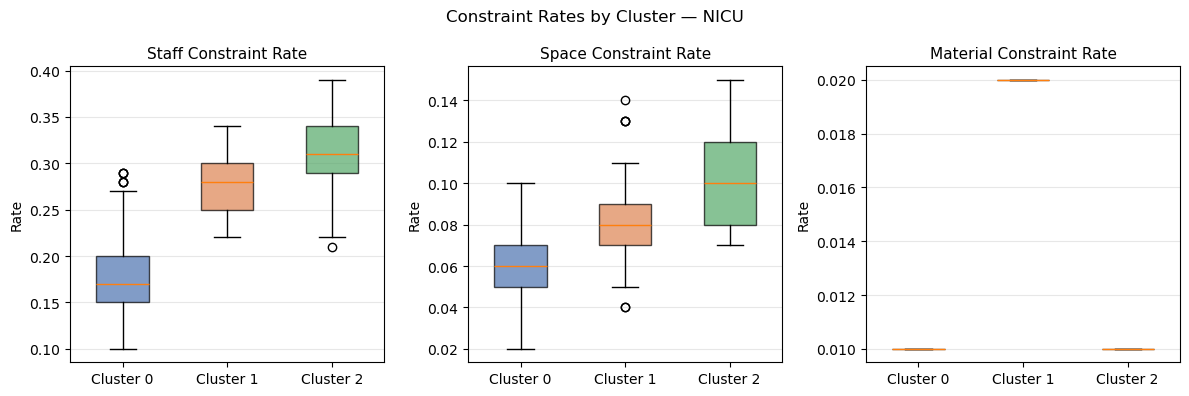


=== Done ===


In [60]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Load data and filter NICU
# ──────────────────────────────────────────────
df = pd.read_csv('Intensivregister_file.csv', sep=';', decimal=',', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

numeric_cols = ['reporting_units', 'current_covid_cases', 'icu_beds_occupied', 'icu_beds_available',
                'material_constraints', 'staff_constraints', 'space_constraints', 'total_icu_capacity',
                'utilization_rate', 'slack_rate', 'staff_constraint_rate', 'material_constraint_rate',
                'space_constraint_rate', 'utilization_rate_z', 'slack_rate_z',
                'staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

nicu = df[df['care_group'] == 'NICU'].copy()
nicu.reset_index(drop=True, inplace=True)

print(f"NICU observations: {len(nicu)}")
print(f"Date range: {nicu['date'].iloc[0]} — {nicu['date'].iloc[-1]}")

# ──────────────────────────────────────────────
# 2. Features (z-scores)
# ──────────────────────────────────────────────
features_z = ['staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']
X = nicu[features_z].values

# ──────────────────────────────────────────────
# 3. Silhouette + Davies-Bouldin for k = 2 to 10
# ──────────────────────────────────────────────
sil_scores = {}
dav_scores = {}

print("\n=== Cluster Validation — NICU ===\n")
print(f"{'k':>3}  {'Silhouette':>12}  {'Davies-Bouldin':>15}")
print("-" * 35)

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    sil = silhouette_score(X, labels)
    dav = davies_bouldin_score(X, labels)
    sil_scores[k] = sil
    dav_scores[k] = dav
    print(f"{k:>3}  {sil:>12.4f}  {dav:>15.4f}")

best_sil = max(sil_scores, key=sil_scores.get)
best_dav = min(dav_scores, key=dav_scores.get)

print(f"\n=== Optimal k ===")
print(f"  Silhouette (highest):       k = {best_sil}  ({sil_scores[best_sil]:.4f})")
print(f"  Davies-Bouldin (lowest):    k = {best_dav}  ({dav_scores[best_dav]:.4f})")

# ──────────────────────────────────────────────
# 4. PLOT — Silhouette + Davies-Bouldin
# ──────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ks = list(sil_scores.keys())
ax1.plot(ks, list(sil_scores.values()), 'o-', color='steelblue', linewidth=2, markersize=6)
ax1.axvline(best_sil, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_sil}')
ax1.set_xlabel('k', fontsize=11)
ax1.set_ylabel('Score', fontsize=11)
ax1.set_title('Silhouette Score (higher = better)', fontsize=12)
ax1.set_xticks(ks)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(ks, list(dav_scores.values()), 'o-', color='mediumpurple', linewidth=2, markersize=6)
ax2.axvline(best_dav, color='red', linestyle='--', alpha=0.7, label=f'Optimal k = {best_dav}')
ax2.set_xlabel('k', fontsize=11)
ax2.set_ylabel('Score', fontsize=11)
ax2.set_title('Davies-Bouldin Index (lower = better)', fontsize=12)
ax2.set_xticks(ks)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('Cluster Validation — NICU', fontsize=13)
plt.tight_layout()
plt.savefig('H1_nicu_validation.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 5. K-Means with k = 2
#    (check validation results — if k=3 is better, change n_clusters=3)
# ──────────────────────────────────────────────
km = KMeans(n_clusters=3, n_init=10, random_state=42)
nicu['cluster'] = km.fit_predict(X)

overall_sil = silhouette_score(X, nicu['cluster'].values)
sil_vals = silhouette_samples(X, nicu['cluster'].values)
nicu['silhouette'] = sil_vals

print(f"\nOverall Silhouette Score (k=2): {overall_sil:.4f}")

# ──────────────────────────────────────────────
# 6. Cluster characterization
# ──────────────────────────────────────────────
report_vars = ['utilization_rate', 'slack_rate',
               'staff_constraint_rate', 'space_constraint_rate',
               'material_constraint_rate']

n_clusters = len(nicu['cluster'].unique())

print(f"\n=== Cluster Characterization (k = {n_clusters}) ===")
for c in sorted(nicu['cluster'].unique()):
    mask = nicu['cluster'] == c
    n = mask.sum()
    pct = n / len(nicu) * 100
    neg_sil = (nicu.loc[mask, 'silhouette'] < 0).sum()
    neg_pct = neg_sil / n * 100
    mean_sil = nicu.loc[mask, 'silhouette'].mean()

    print(f"\n  Cluster {c}:  n = {n} ({pct:.1f}%)")
    print(f"    Per-cluster silhouette score: {mean_sil:.4f}")
    print(f"    Negative silhouette observations: {neg_sil} ({neg_pct:.2f}%)")
    for v in report_vars:
        m = nicu.loc[mask, v].mean()
        s = nicu.loc[mask, v].std()
        print(f"    {v:<28s}  mean = {m:.4f}  (SD = {s:.4f})")

# ──────────────────────────────────────────────
# 7. Centroids (z-score scale)
# ──────────────────────────────────────────────
print(f"\n=== Cluster Centroids (z-score scale) ===")
for c in range(n_clusters):
    vals = ', '.join([f"{features_z[i]} = {km.cluster_centers_[c, i]:.4f}" for i in range(len(features_z))])
    print(f"  Cluster {c}: {vals}")

# ──────────────────────────────────────────────
# 8. PLOT — Silhouette coefficient per cluster
# ──────────────────────────────────────────────
cluster_colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(7, 4))
y_lower = 10

for c in sorted(nicu['cluster'].unique()):
    cluster_sil = np.sort(sil_vals[nicu['cluster'].values == c])
    size = len(cluster_sil)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                      facecolor=cluster_colors[c], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size, f'Cluster {c}', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

ax.axvline(x=overall_sil, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {overall_sil:.4f}')
ax.set_xlabel('Silhouette Coefficient', fontsize=11)
ax.set_ylabel('Observations (sorted)', fontsize=11)
ax.set_title(f'Silhouette Plot — NICU (k = {n_clusters})', fontsize=12)
ax.legend(fontsize=10)
ax.set_yticks([])
plt.tight_layout()
plt.savefig('H1_nicu_silhouette_plot.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 9. PLOT — Scatter staff vs space by cluster
# ──────────────────────────────────────────────
centroids_orig = []
for c in range(n_clusters):
    means = [nicu.loc[nicu['cluster'] == c, f.replace('_z', '')].mean() for f in features_z]
    centroids_orig.append(means)

fig, ax = plt.subplots(figsize=(7, 5))
for c in sorted(nicu['cluster'].unique()):
    mask = nicu['cluster'] == c
    ax.scatter(nicu.loc[mask, 'staff_constraint_rate'],
               nicu.loc[mask, 'space_constraint_rate'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.5, s=20, edgecolors='w', linewidth=0.3)

for c in range(n_clusters):
    ax.scatter(centroids_orig[c][0], centroids_orig[c][2],
               c=cluster_colors[c], marker='X', s=150, edgecolors='black', linewidth=1.5, zorder=5)

ax.set_xlabel('Staff Constraint Rate', fontsize=11)
ax.set_ylabel('Space Constraint Rate', fontsize=11)
ax.set_title('Clusters — Staff vs Space Constraint Rate (NICU)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('H1_nicu_scatter_staff_space.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 10. PLOT — Boxplots constraint rates by cluster
# ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
box_vars = ['staff_constraint_rate', 'space_constraint_rate', 'material_constraint_rate']
box_titles = ['Staff Constraint Rate', 'Space Constraint Rate', 'Material Constraint Rate']

cluster_labels = [f'Cluster {c}' for c in sorted(nicu['cluster'].unique())]

for ax, var, title in zip(axes, box_vars, box_titles):
    data_list = [nicu.loc[nicu['cluster'] == c, var].values for c in sorted(nicu['cluster'].unique())]
    bp = ax.boxplot(data_list, tick_labels=cluster_labels, patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], cluster_colors[:n_clusters]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('Rate', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Constraint Rates by Cluster — NICU', fontsize=12)
plt.tight_layout()
plt.savefig('H1_nicu_boxplots.png', dpi=150)
plt.show()

print("\n=== Done ===")